In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
import yfinance as yf

In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'SUZB3.SA'

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base.tail(10)

[SUZB3.SA] Cache existente cobre de 2020-01-02 a 2025-06-09.
[SUZB3.SA] Cache cobre período solicitado (2022-12-21 a 2025-06-08).
[SUZB3.SA] Retornando 613 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20211221_20250609.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-09.
[^BVSP] Cache cobre período solicitado (2022-12-21 a 2025-06-08).
[^BVSP] Retornando 613 linhas para o período solicitado.


,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,...,atr_pct,tr_pct,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov
data,,,,,,,,,,,,,,,,,,,,,
2025-05-26,53.099998,53.099998,52.060001,52.759998,2931100,-0.003776,0.008181,52.090054,0.236251,0.064089,...,0.022120,0.019712,14.75,0.43,5.6619,137824.0,138800.0,137795.0,138136.0,5553800
2025-05-27,52.509998,52.599998,50.900002,51.310001,14854900,-0.027483,0.010676,41.608218,0.104151,0.072101,...,0.023710,0.036250,14.75,0.43,5.6539,138136.0,140382.0,138136.0,139541.0,11187800
2025-05-28,51.200001,52.040001,51.060001,51.060001,4793300,-0.004872,0.010647,40.109608,-0.020476,0.053586,...,0.023495,0.019193,14.75,0.43,5.6936,139541.0,139547.0,138580.0,138888.0,9735000
2025-05-29,50.990002,51.419998,50.259998,50.580002,8144300,-0.009401,0.008381,37.329587,-0.156176,0.011633,...,0.023662,0.022934,14.75,0.43,5.6559,138869.0,139108.0,137993.0,138534.0,8826400
2025-05-30,50.610001,50.680000,49.349998,49.650002,10637600,-0.018387,0.009105,32.613099,-0.334901,-0.057673,...,0.024297,0.026788,14.75,0.43,5.7087,138546.0,138637.0,136726.0,137027.0,15141600
2025-06-02,49.950001,50.259998,49.439999,49.580002,7892100,-0.001410,0.009301,32.282478,-0.476696,-0.141478,...,0.023775,0.016539,14.75,0.43,5.6937,137026.0,138471.0,136483.0,136787.0,9100100
2025-06-03,49.509998,51.040001,49.500000,50.400002,7827500,0.016539,0.011916,39.960939,-0.516943,-0.216571,...,0.023900,0.030556,14.75,0.43,5.6694,136787.0,137672.0,136175.0,137546.0,9696700
2025-06-04,50.410000,50.500000,49.650002,49.759998,7379100,-0.012698,0.011725,36.483769,-0.593639,-0.291985,...,0.023698,0.017082,14.75,0.43,5.6332,137547.0,138797.0,136695.0,137002.0,10199100
2025-06-05,52.720001,53.150002,50.709999,52.900002,21243900,0.063103,0.025070,56.488319,-0.396479,-0.312883,...,0.025277,0.064083,14.75,0.43,5.5969,137003.0,137451.0,136031.0,136236.0,9484500


## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-05-26,1.167061,0.022120,1.039997,0.019712
2025-05-27,1.216556,0.023710,1.859997,0.036250
2025-05-28,1.199659,0.023495,0.980000,0.019193
2025-05-29,1.196827,0.023662,1.160000,0.022934
2025-05-30,1.206339,0.024297,1.330002,0.026788
2025-06-02,1.178743,0.023775,0.820000,0.016539
2025-06-03,1.204548,0.023900,1.540001,0.030556
2025-06-04,1.179223,0.023698,0.849998,0.017082
2025-06-05,1.337135,0.025277,3.390003,0.064083


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 2.53%
Valorização sugerida: 3.80%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [9]:
valorizacao = 0.04
DIAS_FUTURO = 6  # dias futuros para buscar a valorização

In [10]:
df = pp.calcular_target(df_base, x_pct=valorizacao, dias_futuro=DIAS_FUTURO)

In [11]:
df['Target'].value_counts(normalize=True)

Target
0.0    0.782537
1.0    0.217463
Name: proportion, dtype: float64

In [12]:
# Preparar X e y para treino
DIAS_JANELA_X = 45  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True)    

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

In [15]:
modelo = RandomForestClassifier(n_estimators=200,
                                        max_depth=3,
                                        min_samples_leaf=50,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1,
                                        class_weight='balanced'

                                        )
modelo.fit(X_train.values, y_train.values)

tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)


AUC no treino: 0.876
AUC na validação: 0.940
Diferença AUC (Treino - Validação): -0.065


(np.float64(0.8757847966772916),
 np.float64(0.9404761904761905),
 np.float64(-0.06469139379889888))

Avaliar e logar modelo
MLflow Run ID: 31d178a569a549b0a77030a35f25eb1b para SUZB3.SA_45dias_x_0.04val_6dias_alvo
AUC no treino: 0.876
AUC na validação: 0.940

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.62
  Precisão Média Esperada: 82.33%
  Recall Médio Esperado: 27.82%
  Janelas Usadas para Precisão: 205.0

Threshold ideal baseado em recall mínimo: 0.62

--- Conjunto de Validação --- Janelas
Precisão média (em 23 janelas com previsão positiva): 0.488
Recall médio: 0.160
Sinais de compra presentes na vallidação: 6.0
Sinais de compra previstos na validação: 5
Modelo SUZB3.SA_45dias_x_0.04val_6dias_alvo salvo na run 31d178a569a549b0a77030a35f25eb1b


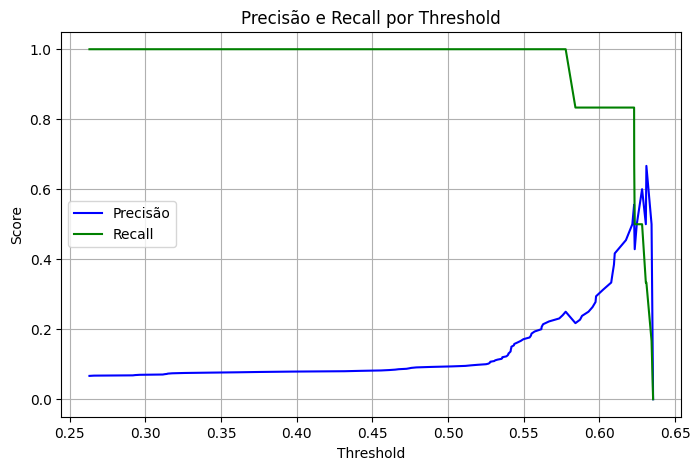

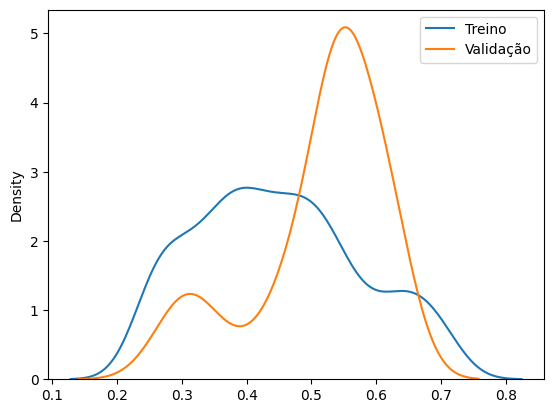

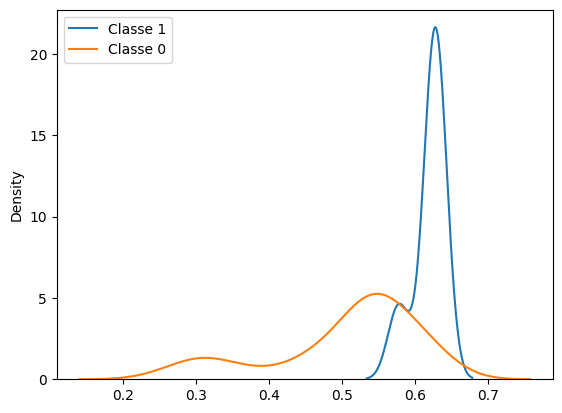

In [19]:
recall_minimo = 0.25  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(modelo, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [20]:
from sklearn.calibration import CalibratedClassifierCV


calibrated_model = CalibratedClassifierCV(modelo, method='isotonic', cv=5)
calibrated_model.fit(X_train.values, y_train.values)

CalibratedClassifierCV(cv=5,
                       estimator=RandomForestClassifier(class_weight='balanced',
                                                        max_depth=3,
                                                        min_samples_leaf=50,
                                                        n_estimators=200,
                                                        n_jobs=-1,
                                                        random_state=42),
                       method='isotonic')

Avaliar e logar modelo
MLflow Run ID: b2a6fcc38c454ad687feb929b17f6bfd para SUZB3.SA_45dias_x_0.04val_6dias_alvo
AUC no treino: 0.868
AUC na validação: 0.902

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.54
  Precisão Média Esperada: 81.05%
  Recall Médio Esperado: 38.62%
  Janelas Usadas para Precisão: 244.0

Threshold ideal baseado em recall mínimo: 0.54

--- Conjunto de Validação --- Janelas
Precisão média (em 41 janelas com previsão positiva): 0.155
Recall médio: 0.309
Sinais de compra presentes na vallidação: 6.0
Sinais de compra previstos na validação: 16
Modelo SUZB3.SA_45dias_x_0.04val_6dias_alvo salvo na run b2a6fcc38c454ad687feb929b17f6bfd


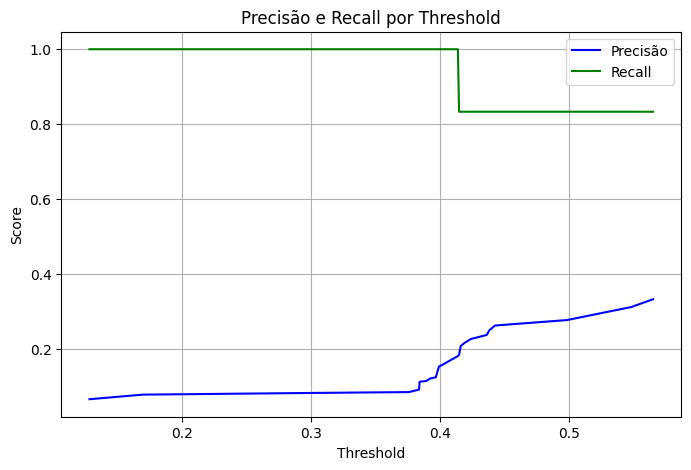

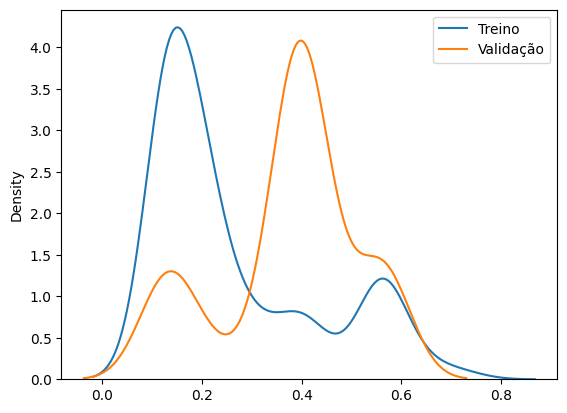

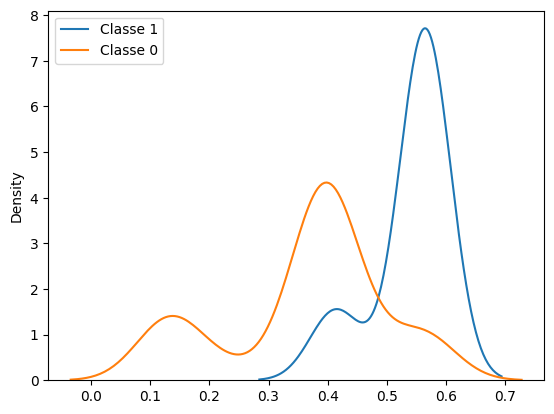

In [21]:
recall_minimo = 0.2  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(calibrated_model, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)


# Redução de features

## Eliminação por correlação

In [18]:
X_filtrado, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
print("Features removidas por alta correlação:", removidas)

Features removidas por alta correlação: ['macd_ultimo', 'macd_conf_ultimo', 'macd_signal_std', 'close_std', 'ibov_amplitude', 'macd_ultimo_norm_atr', 'dias_alta_pct', 'macd_signal_ultimo_norm_atr', 'close_min', 'close_amplitude', 'volume_mean', 'macd_hist_ultimo_norm_atr', 'macd_conf_mean', 'close_mean', 'tr_pct_mean', 'close_ult_vs_mm_janela', 'close_amplitude_norm_atr', 'retorno_mean', 'tr_ultimo_norm_atr', 'rsi_mean', 'macd_mean']


In [19]:
# Importâncias
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)


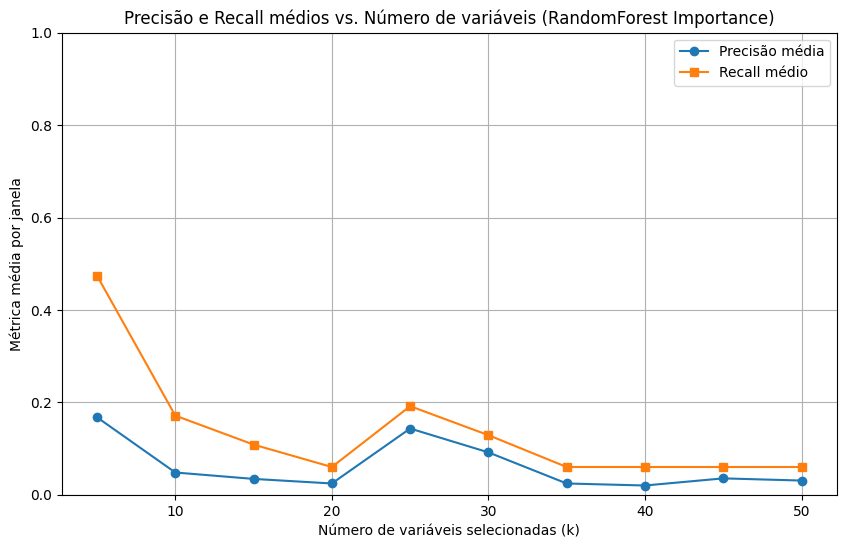

In [20]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


# Features reduzidas

In [22]:
n_features = 45
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['rsi_std',
 'ipca_ultimo',
 'rsi_volatilidade',
 'close_min',
 'retorno_medio_neg',
 'volume_std',
 'macd_signal_ultimo',
 'dolar_trend',
 'close_mean',
 'volume_mean',
 'close_dist_min',
 'macd_signal_mean',
 'dolar_std',
 'ibov_trend',
 'macd_hist_std',
 'macd_hist_abs_mean',
 'ibov_amplitude',
 'macd_conf_mean',
 'retorno_std',
 'retorno_medio_pos',
 'rsi_mean',
 'macd_hist_abs_ultimo',
 'macd_conf_ultimo',
 'ibov_std',
 'macd_mean',
 'macd_ultimo',
 'close_trend',
 'close_std',
 'retorno_mean',
 'volume_trend',
 'macd_signal_std',
 'dolar_ultimo',
 'close_max',
 'close_ult_vs_mm',
 'dias_alta_pct',
 'close_amplitude',
 'retorno_acumulado',
 'macd_hist_mean',
 'selic_ultimo',
 'macd_std',
 'dias_queda_pct',
 'macd_hist_ultimo',
 'rsi_ultimo',
 'retorno_desde_mudanca_close',
 'retorno_desde_mudanca_dolar']

In [23]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [30]:
modelo_reduzido = RandomForestClassifier(n_estimators=200,
                                        max_depth=5,
                                        #min_samples_split=50,
                                        min_samples_leaf=20,                                        
                                        max_features=0.2,
                                        random_state=42,
                                        n_jobs=-1
                                        )
modelo_reduzido.fit(X_train_reduzido.values, y_train.values)
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.935
AUC na validação: 0.678
Diferença AUC (Treino - Validação): 0.257
PROVÁVEL OVERFITTING


Avaliar e logar modelo
MLflow Run ID: 005176776fb94b97be533e8e09eca682 para VALE3.SA_60dias_x_0.03val_8dias_alvo
AUC no treino: 0.935
AUC na validação: 0.678

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.52
  Precisão Média Esperada: 96.34%
  Recall Médio Esperado: 34.37%
  Janelas Usadas para Precisão: 235.0

Threshold ideal baseado em recall mínimo: 0.52

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 44.0
Sinais de compra previstos na validação: 0
Modelo VALE3.SA_60dias_x_0.03val_8dias_alvo salvo na run 005176776fb94b97be533e8e09eca682


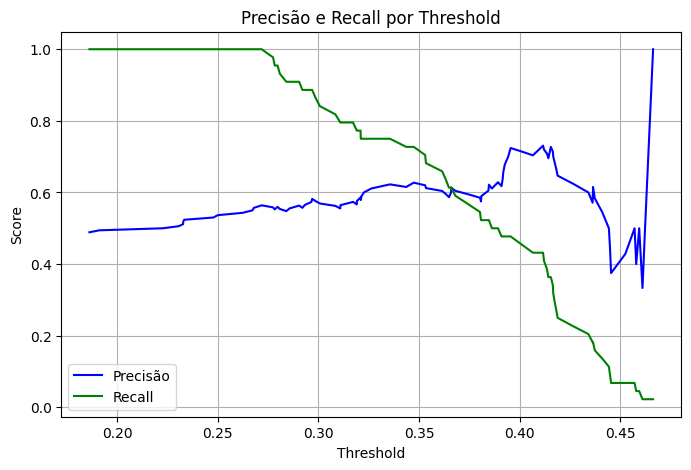

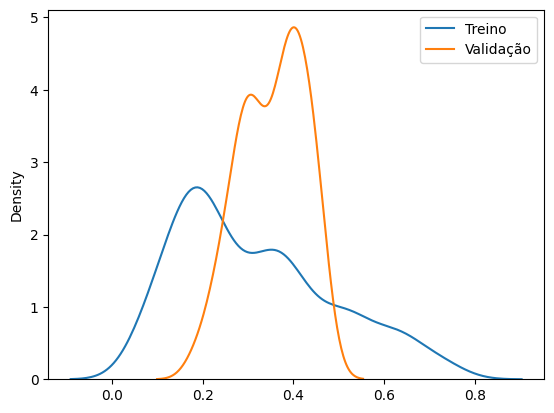

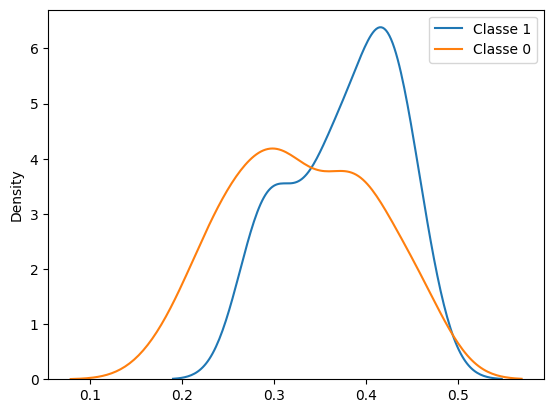

In [32]:
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=0.3)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

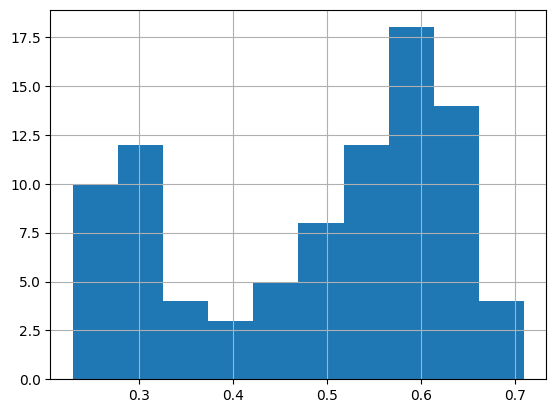

In [24]:
pd.Series(probas).hist()